In [ ]:
# 1. Librerias basicas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# 2. Cargamos el Titanic desde una URL publica (sin contrasena, funciona en cualquier PC/Colab)
# Fuente espejo del clasico dataset de Kaggle
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Estilo de graficos para la clase
sns.set_theme(style="whitegrid", palette="pastel")
plt.rcParams["figure.figsize"] = (8, 5)

print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")
df.head()


Filas: 891, Columnas: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


--- Tipos y nulos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Nulos por columna:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin  

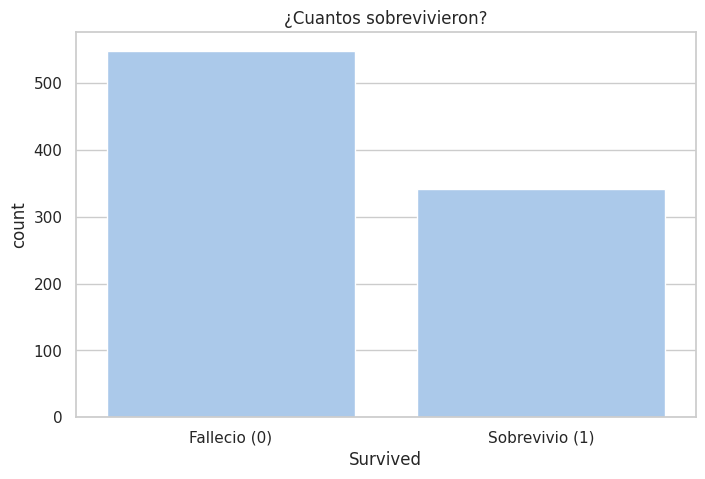

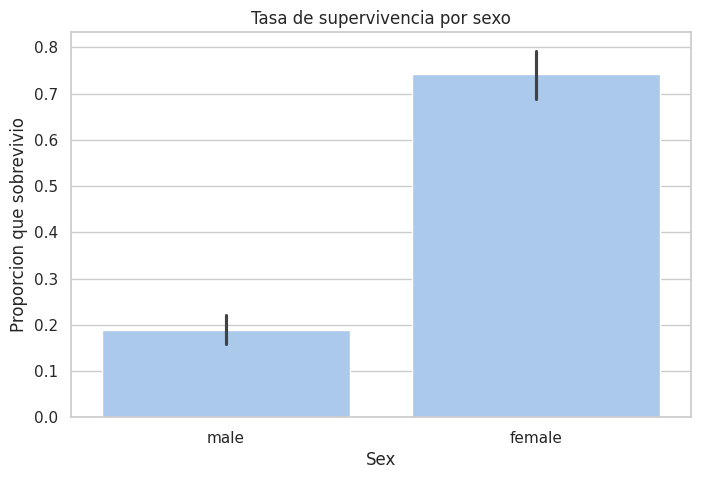

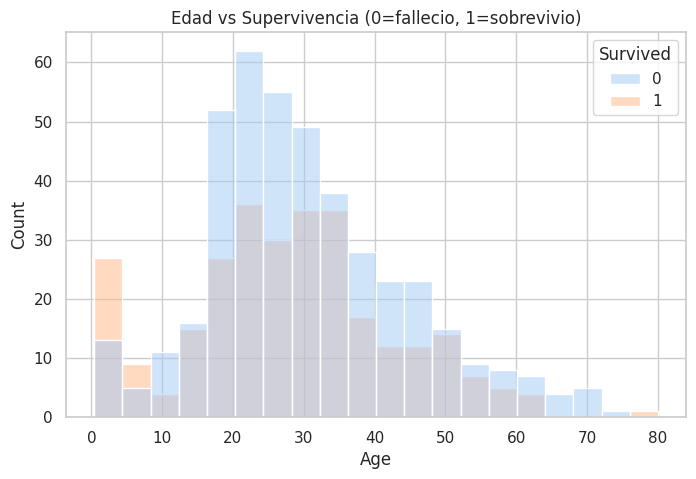

In [ ]:
# 2. Exploramos antes de modelar: ¿como son los datos?
# Para adultos que empiezan: primero mirar, despues modelar.

print("--- Tipos y nulos ---")
print(df.info())
print("\nNulos por columna:")
print(df.isnull().sum())

print("\nProporcion de supervivencia:")
print(df["Survived"].value_counts(normalize=True).round(3))
# 0 = fallecio (~62%), 1 = sobrevivio (~38%). Esta desbalanceado, lo recordaremos al separar train/test.

# Grafico 1: ¿cuantos sobrevivieron?
plt.figure()
sns.countplot(x="Survived", data=df)
plt.xticks([0,1], ["Fallecio (0)", "Sobrevivio (1)"])
plt.title("¿Cuantos sobrevivieron?")
plt.show()

# Grafico 2: ¿el sexo influyo?
plt.figure()
sns.barplot(x="Sex", y="Survived", data=df)
plt.title("Tasa de supervivencia por sexo")
plt.ylabel("Proporcion que sobrevivio")
plt.show()
# Pregunta para la clase: ¿que grupo tiene barra mas alta? ¿Por que creen?

# Grafico 3: ¿la edad influyo?
plt.figure()
sns.histplot(x="Age", hue="Survived", data=df, bins=20, kde=False)
plt.title("Edad vs Supervivencia (0=fallecio, 1=sobrevivio)")
plt.show()


In [ ]:
# 3. Preparacion para el modelo
# Los arboles no entienden texto como "male"/"female", necesitan numeros.
# Tampoco les gusta que falten datos. Y a diferencia de KNN o Regresion Logistica, NO necesitan escalar.

df_arbol = df.copy()

# 3.1 Codificamos Sex: male=0, female=1
# Lo guardamos en columna nueva para no perder la original
df_arbol["Sex_encoded"] = df_arbol["Sex"].map({"male": 0, "female": 1})

# 3.2 Elegimos solo 5 variables simples para empezar (menos es mas al aprender)
columnas = ["Survived", "Pclass", "Sex_encoded", "Age", "SibSp", "Parch"]
print(f"Antes de limpiar: {df_arbol.shape[0]} filas")
df_arbol = df_arbol[columnas].dropna()  # dropna elimina filas con Age vacio (~20% del dataset)
print(f"Despues de dropna: {df_arbol.shape[0]} filas (perdimos ~177, en produccion imputariamos)")

# 3.3 Separamos X (lo que sabe el modelo) e y (lo que debe adivinar)
X = df_arbol.drop(columns="Survived")
y = df_arbol["Survived"]

X.head()

Antes de limpiar: 891 filas
Despues de dropna: 714 filas (perdimos ~177, en produccion imputariamos)


,Pclass,Sex_encoded,Age,SibSp,Parch
0,3,0,22.0,1,0
1,1,1,38.0,1,0
2,3,1,26.0,0,0
3,1,1,35.0,1,0
4,3,0,35.0,0,0


Train: 571 pasajeros, Test: 143 pasajeros
Exactitud en TRAIN: 0.811
Exactitud en TEST : 0.776
Profundidad: 3, Hojas: 8


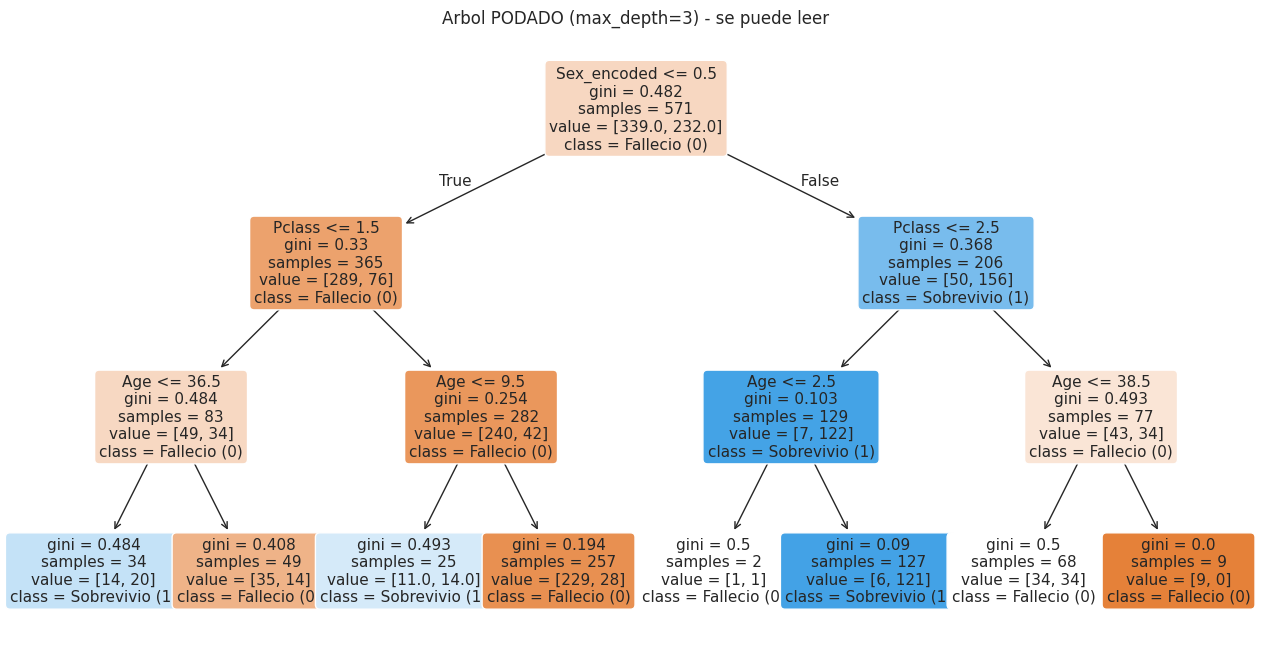

In [ ]:
# 4. Separamos entrenamiento (80%) y prueba (20%) + entrenamos ARBOL SIMPLE primero
# random_state=42 -> fija el azar para que a todos nos de el mismo corte y podamos comparar.
# stratify=y -> mantiene en train y test el mismo 62%/38% de fallecidos/sobrevivientes.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train: {X_train.shape[0]} pasajeros, Test: {X_test.shape[0]} pasajeros")

# Empezamos con max_depth=3 (solo 3 preguntas) para que el arbol sea legible
arbol_podado = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol_podado.fit(X_train, y_train)

print(f"Exactitud en TRAIN: {arbol_podado.score(X_train, y_train):.3f}")
print(f"Exactitud en TEST : {arbol_podado.score(X_test, y_test):.3f}")
print(f"Profundidad: {arbol_podado.get_depth()}, Hojas: {arbol_podado.get_n_leaves()}")
# Si train y test son parecidos (~0.78 vs ~0.77), el modelo generaliza. Si train=1.0 y test mucho menor, memorizo.

plt.figure(figsize=(16, 8))
plot_tree(arbol_podado, feature_names=X.columns, class_names=["Fallecio (0)", "Sobrevivio (1)"], filled=True, rounded=True, fontsize=11)
plt.title("Arbol PODADO (max_depth=3) - se puede leer")
plt.show()
# Como leerlo: cada caja es una pregunta. Ej: "Sex_encoded <= 0.5" significa "¿es hombre?". gini mide impureza (0 = puro).


In [ ]:
# 5. Evaluamos el arbol SIMPLE
y_pred_podado = arbol_podado.predict(X_test)

# Precision / Recall en lenguaje simple:
# Precision (Sobrevivio): de los que DIJE que sobrevivian, ¿a cuantos acerte?
# Recall (Sobrevivio): de los que REALMENTE sobrevivieron, ¿a cuantos encontre?
print("Reporte - Arbol podado (max_depth=3):\n")
print(classification_report(y_test, y_pred_podado, target_names=["Fallecio (0)", "Sobrevivio (1)"]))

# Matriz de confusion en orden ESTANDAR [0,1]:
# Filas = realidad, Columnas = prediccion
# [VN, FP]
# [FN, VP]
cm_podado = confusion_matrix(y_test, y_pred_podado, labels=[0, 1])

# Creamos etiquetas que muestran numero + significado en cada celda
# VN=Verdadero Negativo, FP=Falso Positivo, FN=Falso Negativo, VP=Verdadero Positivo
import numpy as np
nombres = np.array([["VN", "FP"], ["FN", "VP"]])
anot = np.array([[f"{nom}\n{val}" for nom, val in zip(fila_n, fila_v)] for fila_n, fila_v in zip(nombres, cm_podado)])

plt.figure(figsize=(8, 6))
sns.heatmap(cm_podado, annot=anot, fmt="", cmap="Blues", cbar=False, linewidths=1, linecolor="white",
            xticklabels=["Predice Fallecio (0)", "Predice Sobrevivio (1)"],
            yticklabels=["Real Fallecio (0)", "Real Sobrevivio (1)"])
plt.title("Matriz de Confusion - Arbol PODADO\nVN=acierta fallecio | VP=acierta sobrevivio | FP/FN=errores", fontsize=12, pad=15)
plt.xlabel("Prediccion del modelo")
plt.ylabel("Valor real")
plt.show()

print("Guia: VN (arriba-izq) y VP (abajo-der) son aciertos. FP y FN son errores.")
print(f"Ejemplo: VN={cm_podado[0,0]}, FP={cm_podado[0,1]}, FN={cm_podado[1,0]}, VP={cm_podado[1,1]}")

# ¿Que variable peso mas?
import pandas as pd
imp = pd.Series(arbol_podado.feature_importances_, index=X.columns).sort_values()
plt.figure()
imp.plot(kind="barh")
plt.title("Importancia de cada variable (arbol podado)")
plt.xlabel("Peso")
plt.show()